# Pneumonia detection Computer Vision Project using chest xray dataset.

In [2]:
!pip install kaggle


[notice] A new release of pip is available: 26.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import os
import sys

def setup_kaggle():
    if 'google.colab' in sys.modules:
        # Colab setup
        from google.colab import files
        files.upload()
        os.makedirs("/root/.kaggle", exist_ok=True)
        !mv kaggle.json /root/.kaggle/
        !chmod 600 /root/.kaggle/kaggle.json
    else:
        # Local Jupyter setup
        kaggle_path = os.path.expanduser("~/.kaggle/kaggle.json")
        if not os.path.exists(kaggle_path):
            raise FileNotFoundError("❌ kaggle.json not found in ~/.kaggle/")
        else:
            print("✅ kaggle.json found locally")

setup_kaggle()

✅ kaggle.json found locally


In [6]:
!dir C:\Users\User\.kaggle

 Volume in drive C has no label.
 Volume Serial Number is 6EDE-80BE

 Directory of C:\Users\User\.kaggle

10/20/2026  06:50 PM    <DIR>          .
10/20/2026  10:32 AM    <DIR>          ..
10/20/2026  10:43 AM                81 kaggle.json
               1 File(s)             81 bytes
               2 Dir(s)  165,059,792,896 bytes free


In [8]:
!kaggle --version

Kaggle CLI 2.2.3


## Dataset

In [7]:
!kaggle datasets list -s pneumonia

ref                                                            title                                                      size  lastUpdated                 downloadCount  voteCount  usabilityRating  
-------------------------------------------------------------  --------------------------------------------------  -----------  --------------------------  -------------  ---------  ---------------  
paultimothymooney/chest-xray-pneumonia                         Chest X-Ray Images (Pneumonia)                       2463365435  2018-03-24 19:41:59.603000         681977       7750  0.75             
pcbreviglieri/pneumonia-xray-images                            Pneumonia X-Ray Images                               1225740412  2020-05-18 14:32:09.660000          13037        102  0.9375           
iamtapendu/rsna-pneumonia-processed-dataset                    RSNA Pneumonia Processed Dataset                    11748997093  2024-11-10 17:28:20.063000           5714         38  1                


In [2]:
!mkdir data\raw

In [9]:
!kaggle competitions download -c rsna-pneumonia-detection-challenge -p data/raw/

Authentication required to call the Kaggle API.

First, you will need a Kaggle account. You can sign up at
  https://www.kaggle.com/account/login

Recommended: log in with OAuth via a web-based authorization flow.
No token to manage; credentials are cached locally for you.
    kaggle auth login

If you'd rather not use OAuth, generate an API token at
  https://www.kaggle.com/settings/api  (click "Generate New Token" under "API")
and supply it to the CLI in one of these ways:

  Option A: Environment variable
    export KAGGLE_API_TOKEN=xxxxxxxxxxxxxx  # token copied from the settings UI

  Option B: API token file
    Save the token to ~/.kaggle/access_token


In [10]:
!kaggle auth login

Your browser has been opened to visit:
  https://www.kaggle.com/api/v1/oauth2/authorize?response_type=code&client_id=kagglesdk&redirect_uri=http%3A%2F%2Flocalhost%3A8160&scope=resources.admin%3A%2A&state=f5b29c42-3c7e-4d63-ad04-187db5a6bf01&code_challenge=oau1RrfwjINp9SEVL31Jzy0WncFKLQWNG0fD-dzlrRg%3D&code_challenge_method=S256&response_mode=query



You are now logged in as [maanvijangir]



127.0.0.1 - - [21/Oct/2026 11:39:23] "GET /?code=CfDJ8JDwKpgsc5hJpcljKjpYpOF-qdpJ50hCYqnNVPGK3FzZ6MQvKtrEOpzrd_-C6JEUPlHurz3NKY3xujAt64w_SQk34cpMrHGKeZ0_TlempZR43vryqR1DZCZO-nSxhl9aGaR5bwthIEvoqUI0LHhzJ_TTOFLH-PHYQg4bat1JyqI7gf7477qM_oFapskIdthRHuX2I9upBYDk85k9AQLsedC7M2CPLSmCF_cf-mpD8boB35x1HaDzXsUsPDBKs_gsWvZJvL-WqO71ErMyvtdz5enpLvmLLxs1KNXyhb8UoC_ZEXTKoKcgU8EQcddhduk&state=f5b29c42-3c7e-4d63-ad04-187db5a6bf01 HTTP/1.1" 200 -


In [12]:
!kaggle datasets list -s pneumonia

ref                                                            title                                                      size  lastUpdated                 downloadCount  voteCount  usabilityRating  
-------------------------------------------------------------  --------------------------------------------------  -----------  --------------------------  -------------  ---------  ---------------  
paultimothymooney/chest-xray-pneumonia                         Chest X-Ray Images (Pneumonia)                       2463365435  2018-03-24 19:41:59.603000         681977       7750  0.75             
pcbreviglieri/pneumonia-xray-images                            Pneumonia X-Ray Images                               1225740412  2020-05-18 14:32:09.660000          13037        102  0.9375           
iamtapendu/rsna-pneumonia-processed-dataset                    RSNA Pneumonia Processed Dataset                    11748997093  2024-11-10 17:28:20.063000           5714         38  1                


## Unzip Dataset

In [14]:
import zipfile
import os

zip_path = r"C:\Users\User\Computer Vision Project\data\raw\chest-xray-pneumonia.zip"
extract_dir = r"C:\Users\User\Computer Vision Project\data\raw"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

print("Dataset extracted to:", extract_dir)

Dataset extracted to: C:\Users\User\Computer Vision Project\data\raw


In [15]:
base_dir = r"C:\Users\User\Computer Vision Project\data\raw\chest_xray"
for folder in ["train","test","val"]:
    print(folder,":",os.listdir(os.path.join(base_dir, folder))[:5])

train : ['NORMAL', 'PNEUMONIA']
test : ['NORMAL', 'PNEUMONIA']
val : ['NORMAL', 'PNEUMONIA']


In [16]:
for folder in ["train","test","val"]:
    for category in ["NORMAL","PNEUMONIA"]:
        path = os.path.join(base_dir, folder, category)
        print(folder, category, ":", len(os.listdir(path)))
        

train NORMAL : 1341
train PNEUMONIA : 3875
test NORMAL : 234
test PNEUMONIA : 390
val NORMAL : 8
val PNEUMONIA : 8


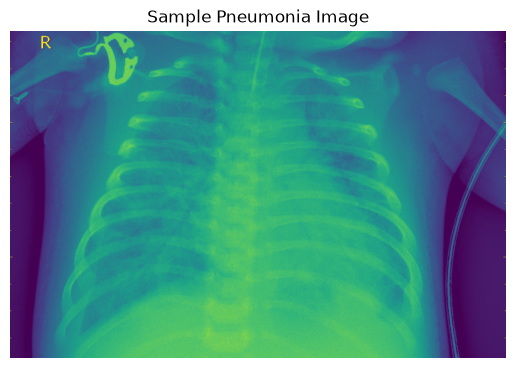

In [18]:
from PIL import Image
import matplotlib.pyplot as plt
import os

sample_path = os.path.join(base_dir, "train", "PNEUMONIA", os.listdir(os.path.join(base_dir, "train", "PNEUMONIA"))[0])
img = Image.open(sample_path)

plt.imshow(img)
plt.title("Sample Pneumonia Image")
plt.axis("off")
plt.show()


## Merge valid folder to train

In [19]:

import shutil

base_dir = r"C:\Users\User\Computer Vision Project\data\raw\chest_xray"

for category in ["NORMAL", "PNEUMONIA"]:
    val_path = os.path.join(base_dir, "val", category)
    train_path = os.path.join(base_dir, "train", category)

    for file in os.listdir(val_path):
        src = os.path.join(val_path, file)
        dst = os.path.join(train_path, file)
        shutil.move(src, dst)

print("Merged val into train")

Merged val into train


## Preprocessing 

In [20]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

train_transform = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

test_transform = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_data = datasets.ImageFolder(os.path.join(base_dir, "train"), transform=train_transform)
test_data  = datasets.ImageFolder(os.path.join(base_dir, "test"), transform=test_transform)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
test_loader  = DataLoader(test_data, batch_size=32, shuffle=False)

print("Train size:", len(train_data))
print("Test size:", len(test_data))

Train size: 5232
Test size: 624


In [21]:
import os

base_dir = r"C:\Users\User\Computer Vision Project\data"
interim_dir = os.path.join(base_dir,"interim")

os.makedirs(interim_dir, exist_ok=True)
print("Interim folder created at:",interim_dir)
